# Reconstructing the global port-operability screening method

**Sources:** Wiegel et al. (2021), [Global Mapping of Seaport Operability Risk Indicators Using Open-Source Metocean Data](https://doi.org/10.3390/jmse9070695), especially section 2 and Appendix A ([local paper](iterature/jmse-09-00695-v2.pdf)); and Wiegel (2020), [MSc thesis](iterature/MSc_Thesis_Matijs_Wiegel_Mapping_port_operability_indicators_across_the_world_final.pdf), especially chapter 3. Equations are implemented in [port_operability.py](port_operability.py), with focused numerical and event-handling tests.

**Default execution is a small REAL-DATA PILOT:** Cape Town, January and July 2018, hourly. It is not the published 1979-2018 global study. All downloaded files, caches, calculated datasets and figures live under `data/`. The digitized points from the other notebook are never used as metocean inputs.

This notebook contains the acquisition, reconstructed coastal grid, offshore-to-nearshore transformation, bound-IG calculation, conditional availability, validation, spatial/seasonal/annual analyses, sensitivity scenarios, exports and figure recipes. Full-global downloads are explicitly gated. No HTML file is saved.

## Reproduction limits and deliberate choices

| Component | Implementation / limitation |
|---|---|
| ERA5 | Actual hourly wind and wave variables from CDS, on a requested 0.5-degree grid. Six time-varying variables plus static model bathymetry. |
| Coastal sampling | Current Natural Earth 1:10m coastline and land polygons; nearest eligible wet grid point 0.1-0.8 degrees away. The original manual exclusions are unavailable. The reconstructed count is reported, not forced to 4,560. |
| Shore normal | Four neighbouring vertices on each side, within the same coastline segment, with the perpendicular pointing offshore. This follows the paper's tangent description rather than copying indexing/orientation bugs in the old notebook. |
| Port coordinates | Ten approximate geographic seeds, snapped to reconstructed wet sites; NOT the missing WPI-2019 seed list. Distances and selected coordinates are exported for review. |
| Nearshore waves | Linear dispersion, group-speed shoaling, Snell refraction, original lower refraction bound 0.8, breaking at 0.73 times depth, and a shoreward-direction filter for short waves only. Offshore depths smaller than the target depth are floored as in the original code. |
| Bound IG waves | Appendix A's interaction coefficient, checked visually against the PDF equation. JONSWAP normalized to Hs^2/16, cos(theta/2)^(2s), s=2 or 7, and 0.004-0.04 Hz. The thesis does not specify the gamma(Hs,Tp) implementation or quadrature: **gamma=3.3**, 192 primary frequencies, 72 directions and 19 IG frequencies are explicit reconstructed choices. This is not the original lookup. |
| Lookup grid | Hs=0..12.5 m inclusive (251 rows), Tp=0.1..25 s (250 columns). The documents call a zero-inclusive grid '250 x 250', which is inconsistent with both inclusive endpoints. Interpolation is linear; out-of-domain states raise an error instead of being clipped. |
| Events | Equality to a threshold is unavailable. Interior calm gaps <=4 hours are filled. Missing observations split events; endpoints are not forced calm. Frequency and duration use the merged events, not the inconsistent raw-event calculation in the legacy code. Annualized frequency uses 365.25 days of observed hours. |
| Main driver | Lowest individual conditional availability; short/IG availability differing by <1 percentage point is a joint driver, as indicated in the original figure legend. This is a screening label, not causal attribution. |
| 103 ports | Their original identifiers/coordinates are absent. An optional **user-supplied** 103-port CSV is supported; no unrelated selection is presented as the original sample. |
| Interpretation | Potential pre-intervention metocean operability, NOT measured downtime or a detailed harbour/mooring model. Numeric agreement with the published results is not asserted. |

In [1]:
%matplotlib inline
import calendar
import json
import sys
from dataclasses import asdict
from pathlib import Path

REPOSITORY_ROOT = Path.cwd().parent if Path.cwd().name == 'archive' else Path.cwd()
sys.path.insert(0, str(REPOSITORY_ROOT))

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display
import port_operability as model

DATA_ROOT = REPOSITORY_ROOT / 'data'
PATHS = model.data_directories(DATA_ROOT)
MODE = 'pilot'  # pilot, validation, global, or ports103
ALLOW_LARGE_DOWNLOAD = False
REQUEST_BUDGET = 2
YEARS = [2018] if MODE == 'pilot' else list(range(1979, 2019))
MONTHS = [1, 7] if MODE == 'pilot' else list(range(1, 13))
SCENARIOS = model.SCENARIOS
if MODE not in {'pilot', 'validation', 'global', 'ports103'}:
    raise ValueError('Unknown study mode.')
scope_label = 'REAL-DATA PILOT: Cape Town, January/July 2018' if MODE == 'pilot' else f'{MODE}: {min(YEARS)}-{max(YEARS)}'
print(scope_label)
print('Interpreter:', sys.executable)
print('Data directory:', DATA_ROOT.resolve())
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
COLOURS = {'wind': '#00a390', 'short_wave': '#eb7245', 'ig': '#c41e79'}
RISK_COLOURS = {'Low': '#00cc00', 'Medium': '#ffff33', 'High': '#ff7f50', 'Very high': '#d73027'}

def save_figure(fig, name):
    fig.savefig(PATHS['figures'] / f'{MODE}-{name}.png', dpi=150, bbox_inches='tight')

def world_axes(ax):
    land.plot(ax=ax, facecolor='#eeefee', edgecolor='none')
    ax.set(facecolor='#bfd2d9', xlim=(-180, 180), ylim=(-90, 90), xlabel='Longitude', ylabel='Latitude')
    ax.set_aspect('equal')
    ax.text(0.01, 0.01, 'Natural Earth, public domain', transform=ax.transAxes, fontsize=7)

/Users/mvankoningsveld/Library/CloudStorage/OneDrive-DelftUniversityofTechnology/github/Port-Operability-Metocean/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


REAL-DATA PILOT: Cape Town, January/July 2018
Interpreter: /Users/mvankoningsveld/Library/CloudStorage/OneDrive-DelftUniversityofTechnology/github/Port-Operability-Metocean/.venv/bin/python
Data directory: /Users/mvankoningsveld/Library/CloudStorage/OneDrive-DelftUniversityofTechnology/github/Port-Operability-Metocean/data


## 1. Download reference geometry and ERA5 model bathymetry

CDS credentials stay in `~/.cdsapirc`, never in this notebook. The ERA5 dataset terms must be accepted in the CDS web interface. Requests are cached with request JSON and SHA256 hashes. CDS may return a ZIP of separate atmosphere/wave NetCDF streams; both formats are handled. Requests are monthly because a full-year six-variable pilot was rejected by current CDS cost limits.

The global bathymetry request is a **single static field**, not a global hourly download. Natural Earth files are downloaded into `data/reference/`.

In [2]:
bathymetry_file = model.retrieve_era5(
    model.era5_request(2018, [1], [90, -180, -90, 179.5], variables=['model_bathymetry'], snapshot=True),
    PATHS['raw'] / 'era5-global-bathymetry-20180101.nc',
)
bathymetry = model.open_era5(bathymetry_file)
coast, land = model.download_coastline(DATA_ROOT)
print('ERA5 bathymetry dimensions:', dict(bathymetry.sizes))
print('Coastline features:', len(coast), '| CRS:', coast.crs)

ERA5 bathymetry dimensions: {'time': 1, 'latitude': 361, 'longitude': 720}
Coastline features: 4133 | CRS: EPSG:4326


## 2. Reconstruct the coastal grid and select sites

Only positive finite ocean-model bathymetry outside Natural Earth's land polygons is eligible. Degree-distance searches are periodic at the dateline. Candidates within the 0.1-0.8 degree coastal band are reduced to the nearest eligible site for each coastline vertex, then deduplicated. This is a reconstructed grid: newer coastline data and the missing manual exclusions prevent bit-for-bit matching of the original 4,560 locations.

For `ports103` mode, supply `data/reference/ports-103.csv` with exactly 103 rows and columns `name,port_lon,port_lat`. Selection provenance must be recorded separately; this notebook does not invent the original sample.

In [3]:
grid_file = PATHS['processed'] / 'reconstructed-coastal-grid.csv'
if grid_file.exists():
    grid = pd.read_csv(grid_file)
else:
    grid = model.build_coastal_grid(bathymetry, coast, land)
    grid.to_csv(grid_file, index=False)
validation_sites = model.select_port_sites(grid)
validation_sites.to_csv(PATHS['processed'] / 'validation-sites.csv', index=False)
print(f'Reconstructed coastal sites: {len(grid):,}; paper: 4,560 (not forced to agree).')
display(validation_sites[['name', 'port_lon', 'port_lat', 'lon', 'lat', 'depth0', 'shore_normal', 'port_to_grid_km']])
if MODE == 'global':
    sites = grid.copy()
    active_ports = None
elif MODE == 'ports103':
    supplied_ports = pd.read_csv(PATHS['reference'] / 'ports-103.csv')
    if len(supplied_ports) != 103 or not {'name', 'port_lon', 'port_lat'} <= set(supplied_ports):
        raise ValueError('Provide exactly 103 port seeds with name, port_lon, port_lat.')
    active_ports = model.select_port_sites(grid, supplied_ports)
    sites = active_ports.drop_duplicates('site_id').copy()
else:
    active_ports = validation_sites.loc[validation_sites.name.eq('Cape Town')].copy() if MODE == 'pilot' else validation_sites.copy()
    sites = active_ports.drop_duplicates('site_id').copy()
sites.to_csv(PATHS['processed'] / f'{MODE}-selected-sites.csv', index=False)

Reconstructed coastal sites: 8,358; paper: 4,560 (not forced to agree).


,name,port_lon,port_lat,lon,lat,depth0,shore_normal,port_to_grid_km
0,Doraleh,43.08,11.60,43.5,11.5,22.0,72.510683,47.087891
1,Jeddah,39.16,21.48,39.0,21.5,109.0,246.891492,16.703081
2,Hay Point,149.30,-21.28,149.5,-21.0,6.0,82.589210,37.411304
3,Shanghai,121.60,31.35,122.0,32.0,10.0,63.407068,81.588617
4,Hadera,34.87,32.47,34.5,32.5,236.0,281.530113,34.864636
5,Long Beach,-118.22,33.75,-118.0,33.5,267.0,216.816695,34.462942
6,Tomakomai,141.62,42.63,141.5,42.0,644.0,74.244834,70.744232
7,Salalah,54.00,16.95,54.0,16.5,978.0,166.618059,50.037717
8,Cape Town,18.43,-33.91,18.0,-34.0,123.0,278.075772,40.903524
9,Geraldton,114.60,-28.78,114.5,-29.0,42.0,236.054964,26.328986


## 3. Review the download plan, then retrieve hourly data

Sites are grouped into regional 5-degree tiles and requested **month by month**. Only paired selected points are extracted to compressed monthly NetCDF caches. The original tile responses are retained under `data/raw/` for provenance. A full-global run therefore requires a separately reviewed storage/transfer plan; raw tiles may substantially exceed the ~36 GiB minimum for the original six-variable coastal time series alone.

Switching modes does **not** silently authorize a large download. Review the plan before changing `REQUEST_BUDGET` or `ALLOW_LARGE_DOWNLOAD`. A free-disk-space check also guards the estimated retained tile and point caches. Full-global work can be resumed from cached monthly point files.

In [4]:
plan = model.download_plan(sites, YEARS, MONTHS)
plan_table = pd.DataFrame([{'year': p['year'], 'month': p['month'], 'sites': len(p['site_ids']),
                            'area_n_w_s_e': str(p['request']['area']), 'file': p['filename']} for p in plan])
plan_table.to_csv(PATHS['processed'] / f'{MODE}-download-plan.csv', index=False)
print(f'{len(sites):,} unique sites; {len(plan):,} regional monthly requests before cache reuse.')
display(plan_table.head(12))
model.download_hourly_sites(sites, YEARS, MONTHS, DATA_ROOT,
                            request_budget=REQUEST_BUDGET, allow_large_download=ALLOW_LARGE_DOWNLOAD)
example_site = sites.iloc[0]
example_raw = model.load_site_history(example_site, YEARS, MONTHS, DATA_ROOT)
print('Example point-cache dimensions:', dict(example_raw.sizes))
display(example_raw[['u10', 'v10', 'swh', 'mwd', 'mwp', 'pp1d']].to_dataframe().head())

1 unique sites; 2 regional monthly requests before cache reuse.


,year,month,sites,area_n_w_s_e,file
0,2018,1,1,"[-30, 15, -35, 20]",era5-tile-2018-01-50f37ac958e2.nc
1,2018,7,1,"[-30, 15, -35, 20]",era5-tile-2018-07-9d249daeec6f.nc


Example point-cache dimensions: {'time': 1488}


,u10,v10,swh,mwd,mwp,pp1d,number,latitude,expver,longitude
time,,,,,,,,,,
2018-01-01 00:00:00,7.415634,4.229889,2.170602,240.290146,7.136385,7.505470,0,-34.0,0001,18.0
2018-01-01 01:00:00,6.518845,4.221176,2.248606,238.741272,7.282624,7.777687,0,-34.0,0001,18.0
2018-01-01 02:00:00,6.026718,4.232361,2.305275,237.460297,7.442031,8.035988,0,-34.0,0001,18.0
2018-01-01 03:00:00,6.168137,4.309555,2.356417,236.316345,7.582952,8.274269,0,-34.0,0001,18.0
2018-01-01 04:00:00,6.323456,4.786072,2.414665,235.102066,7.689340,8.457375,0,-34.0,0001,18.0


## 4. Nearshore waves and bound infragravity waves

Wind magnitude is `hypot(u10,v10)`. Solve omega^2 = g k tanh(kh), derive phase and group speeds, use `Ks=sqrt(Cg_offshore/Cg_nearshore)` and Snell's law, and apply the refraction and breaking bounds described above. For IG waves, retain all incoming/offshore wave directions as in the study, rather than using the short-wave shoreward filter.

Appendix A gives the difference-interaction coefficient D and `E_IG(df)=2 integral D^2 E(f+df,theta1) E(f,theta2) df dtheta1 dtheta2`. Integrate 0.004-0.04 Hz to obtain `H_IG=4 sqrt(m0)` and `T_IG=m0/m1`. Circular convolution of the directional spreading density reduces the two angular integrals to a difference-angle integral. The primary frequency grid spans 0.2/Tp to 5/Tp. With fixed gamma, bound wave height scales as Hs^2, allowing a full height/period lookup without recomputing the same kernel for every height.

**Scientific limitation:** missing original gamma, angular convention and quadrature mean these are reconstructed IG estimates. A refinement check below assesses numerical sensitivity, not agreement with the missing original lookup.

In [5]:
quadrature_checks = []
for tp in [5, 10, 15]:
    coarse = model.bound_ig_unit(tp)
    refined = model.bound_ig_unit(tp, n_frequency=384, n_direction=144, n_ig=37)
    quadrature_checks.append({'Tp_s': tp, 'unit_Hs_IG_m': coarse[0],
                              'refined_IG_m': refined[0], 'relative_height_difference': abs(coarse[0]/refined[0]-1)})
quadrature_checks = pd.DataFrame(quadrature_checks)
assert (quadrature_checks.relative_height_difference < 0.02).all()
quadrature_checks.to_csv(PATHS['processed'] / 'ig-quadrature-check.csv', index=False)
display(quadrature_checks)
display(pd.DataFrame([asdict(s) for s in SCENARIOS]))

,Tp_s,unit_Hs_IG_m,refined_IG_m,relative_height_difference
0,5,0.006054,0.006053,0.000261
1,10,0.006156,0.006136,0.003347
2,15,0.013914,0.013777,0.009930


,name,depth_m,wind_limit,wave_limit,ig_limit,wind_factor,wave_factor,gap_hours
0,baseline,20.0,13.8,2.0,0.05,1.00,1.00,4
1,lower_thresholds,20.0,10.8,1.5,0.04,1.00,1.00,4
2,higher_thresholds,20.0,17.2,2.5,0.06,1.00,1.00,4
3,depth_17m,17.0,13.8,2.0,0.05,1.00,1.00,4
4,depth_16m,16.0,13.8,2.0,0.05,1.00,1.00,4
5,depth_15m,15.0,13.8,2.0,0.05,1.00,1.00,4
6,wind_plus_5pct,20.0,13.8,2.0,0.05,1.05,1.00,4
7,waves_plus_5pct,20.0,13.8,2.0,0.05,1.00,1.05,4
8,wind_waves_plus_5pct,20.0,13.8,2.0,0.05,1.05,1.05,4


## 5. Conditional availability and scenario calculations

Baseline limits: wind 13.8 m/s, short waves 2.0 m and bound IG waves 0.05 m at 20 m water depth. Fill only **interior** available intervals of at most four consecutive observed hours, then calculate individual and joint conditional availability. Boundary events are counted without changing observations. Discontinuous months, seasons and missing observations are never concatenated into false contiguous events.

The nine scenarios reproduce the thesis' threshold, depth and +5% forcing experiments. Every depth uses its own reconstructed IG lookup. Results include observed hours, merged-event counts, annualized frequency, mean duration, raw/conditional availabilities and indicator p50/p95 values. Short-wave percentiles use shoreward observations only; availability counts seaward observations as non-exceedances. For seasonal summaries, a separate `frequency_per_season` reports events per sampled calendar-year season; incomplete seasons remain incomplete rather than being presented as full-year observations. A legacy-column-alias CSV is also exported.

In [6]:
summary, annual, seasonal = model.run_study(sites, YEARS, MONTHS, DATA_ROOT, SCENARIOS)
baseline = summary.loc[summary.scenario.eq('baseline')].copy()
annual_baseline = annual.loc[annual.scenario.eq('baseline')].copy()
seasonal_baseline = seasonal.loc[seasonal.scenario.eq('baseline')].copy()
print(scope_label)
display(baseline[['site_id', 'name', 'total_availability', 'wind_availability',
                  'short_wave_availability', 'ig_availability', 'frequency', 'duration',
                  'observed_hours', 'risk', 'main_driver']])
with xr.open_dataset(PATHS['processed'] / f'indicators-site-{int(example_site.site_id)}.nc') as ds:
    example_indicators = ds.to_dataframe()
print('These are calculated pilot results, not the digitized image values.')

REAL-DATA PILOT: Cape Town, January/July 2018


,site_id,name,total_availability,wind_availability,short_wave_availability,ig_availability,frequency,duration,observed_hours,risk,main_driver
0,935,Cape Town,55.30914,97.513441,65.860215,61.223118,100.149194,39.117647,1488,Very high,IG waves


These are calculated pilot results, not the digitized image values.


## 6. Figures 1-2: thresholding and individual/joint persistence

The following uses an actual observed two-week window from the current run. It illustrates the published mechanism; it is not a copy of the paper's illustrative time window.

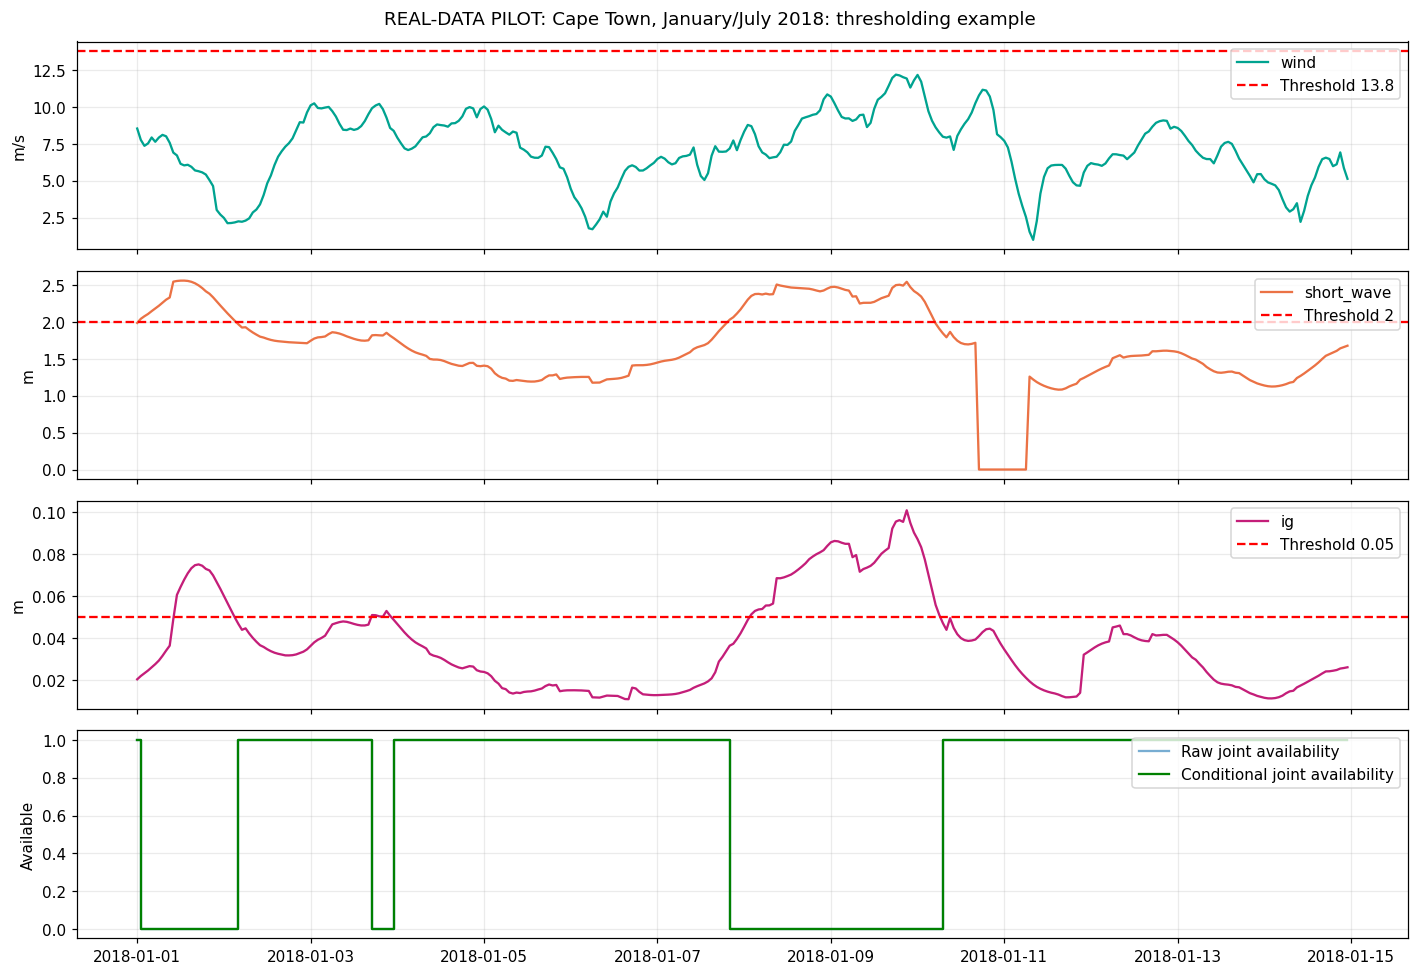

In [7]:
window = example_indicators.loc[example_indicators.index < example_indicators.index[0] + pd.Timedelta(days=14)].copy()
plot_index = pd.date_range(window.index[0], window.index[-1], freq='h')
scenario = SCENARIOS[0]
limits = {'wind': scenario.wind_limit, 'short_wave': scenario.wave_limit, 'ig': scenario.ig_limit}
fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
masks = []
for ax, (indicator, limit) in zip(axes[:3], limits.items()):
    ax.plot(plot_index, window[indicator].reindex(plot_index), color=COLOURS[indicator], label=indicator)
    ax.axhline(limit, color='red', linestyle='--', label=f'Threshold {limit:g}')
    ax.set_ylabel('m/s' if indicator == 'wind' else 'm')
    ax.legend(loc='upper right')
    masks.append(window[indicator].to_numpy() >= limit)
raw_joint = pd.Series(np.logical_or.reduce(masks), index=window.index)
conditioned_joint = raw_joint.copy()
for positions in model.time_segments(window.index):
    conditioned_joint.iloc[positions] = model.merge_short_gaps(raw_joint.iloc[positions], scenario.gap_hours)
axes[3].step(plot_index, (~raw_joint).reindex(plot_index), where='post', label='Raw joint availability', alpha=0.6)
axes[3].step(plot_index, (~conditioned_joint).reindex(plot_index), where='post', label='Conditional joint availability', color='green')
axes[3].set_ylabel('Available')
axes[3].legend(loc='upper right')
fig.suptitle(f'{scope_label}: thresholding example')
fig.tight_layout()
save_figure(fig, 'figures-1-2-thresholding')
plt.show()

## 7. Figure 4 / Table 2: port comparison and validation

Published Table 2 availability is a **reference target only**. Differences for a two-month pilot must not be interpreted as validation error: time coverage, site selection and IG assumptions differ. A confusion matrix is calculated only after a complete 1979-2018, all-month, ten-port run. Even that comparison is against literature classifications, not actual port-operator downtime.

,name,total_availability,wind_availability,short_wave_availability,ig_availability,published_operability
0,Cape Town,55.30914,97.513441,65.860215,61.223118,54.1


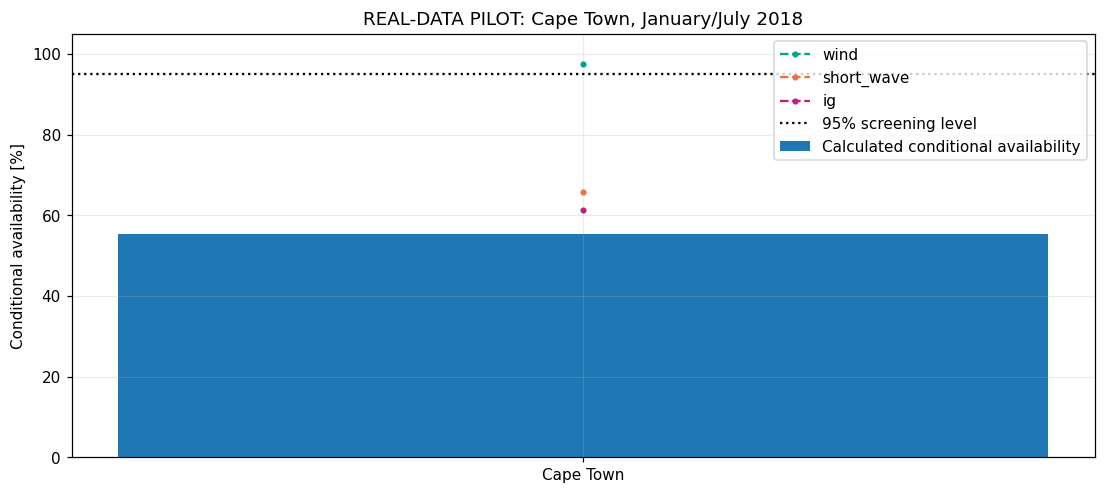

Figure 3 confusion matrix is not claimed for this incomplete/non-validation sample.


In [8]:
if active_ports is not None:
    shared = [c for c in active_ports if c != 'site_id' and c in baseline]
    port_comparison = active_ports.merge(baseline.drop(columns=shared), on='site_id', validate='many_to_one')
    port_comparison.to_csv(PATHS['processed'] / f'{MODE}-port-comparison.csv', index=False)
    columns = ['name', 'total_availability', 'wind_availability', 'short_wave_availability', 'ig_availability']
    if 'published_operability' in port_comparison:
        columns.append('published_operability')
    display(port_comparison[columns])
    fig, ax = plt.subplots(figsize=(12, 5))
    x = np.arange(len(port_comparison))
    ax.bar(x, port_comparison.total_availability, label='Calculated conditional availability')
    for indicator in COLOURS:
        ax.plot(x, port_comparison[f'{indicator}_availability'], '.--', color=COLOURS[indicator], label=indicator)
    ax.axhline(95, color='black', linestyle=':', label='95% screening level')
    ax.set(xticks=x, xticklabels=port_comparison.name, ylim=(0, 105), ylabel='Conditional availability [%]', title=scope_label)
    ax.legend()
    save_figure(fig, 'figure-4-port-comparison')
    plt.show()
else:
    print('Port-specific comparison requires validation or ports103 mode.')

expected_year_hours = annual_baseline.year.map(lambda y: (366 if calendar.isleap(y) else 365) * 24)
complete_annual = annual_baseline.loc[annual_baseline.observed_hours.eq(expected_year_hours)].copy()
full_validation = (MODE == 'validation' and YEARS == list(range(1979, 2019))
                   and MONTHS == list(range(1, 13)) and len(active_ports) == 10
                   and len(complete_annual) == len(sites) * 40)
if full_validation:
    predicted_issues = port_comparison.total_availability <= 95
    confusion = pd.crosstab(port_comparison.known_issues.rename('Literature issues'), predicted_issues.rename('Predicted issues'))
    confusion.to_csv(PATHS['processed'] / 'validation-confusion-matrix.csv')
    display(confusion)
else:
    print('Figure 3 confusion matrix is not claimed for this incomplete/non-validation sample.')

## 8. Figures 5-6: spatial risk levels and dominant drivers

Risk levels follow the paper exactly: P>95 low; 85<P<=95 medium; 75<P<=85 high; P<=75 very high. In pilot mode these maps show only the calculated pilot site, not inferred global results.

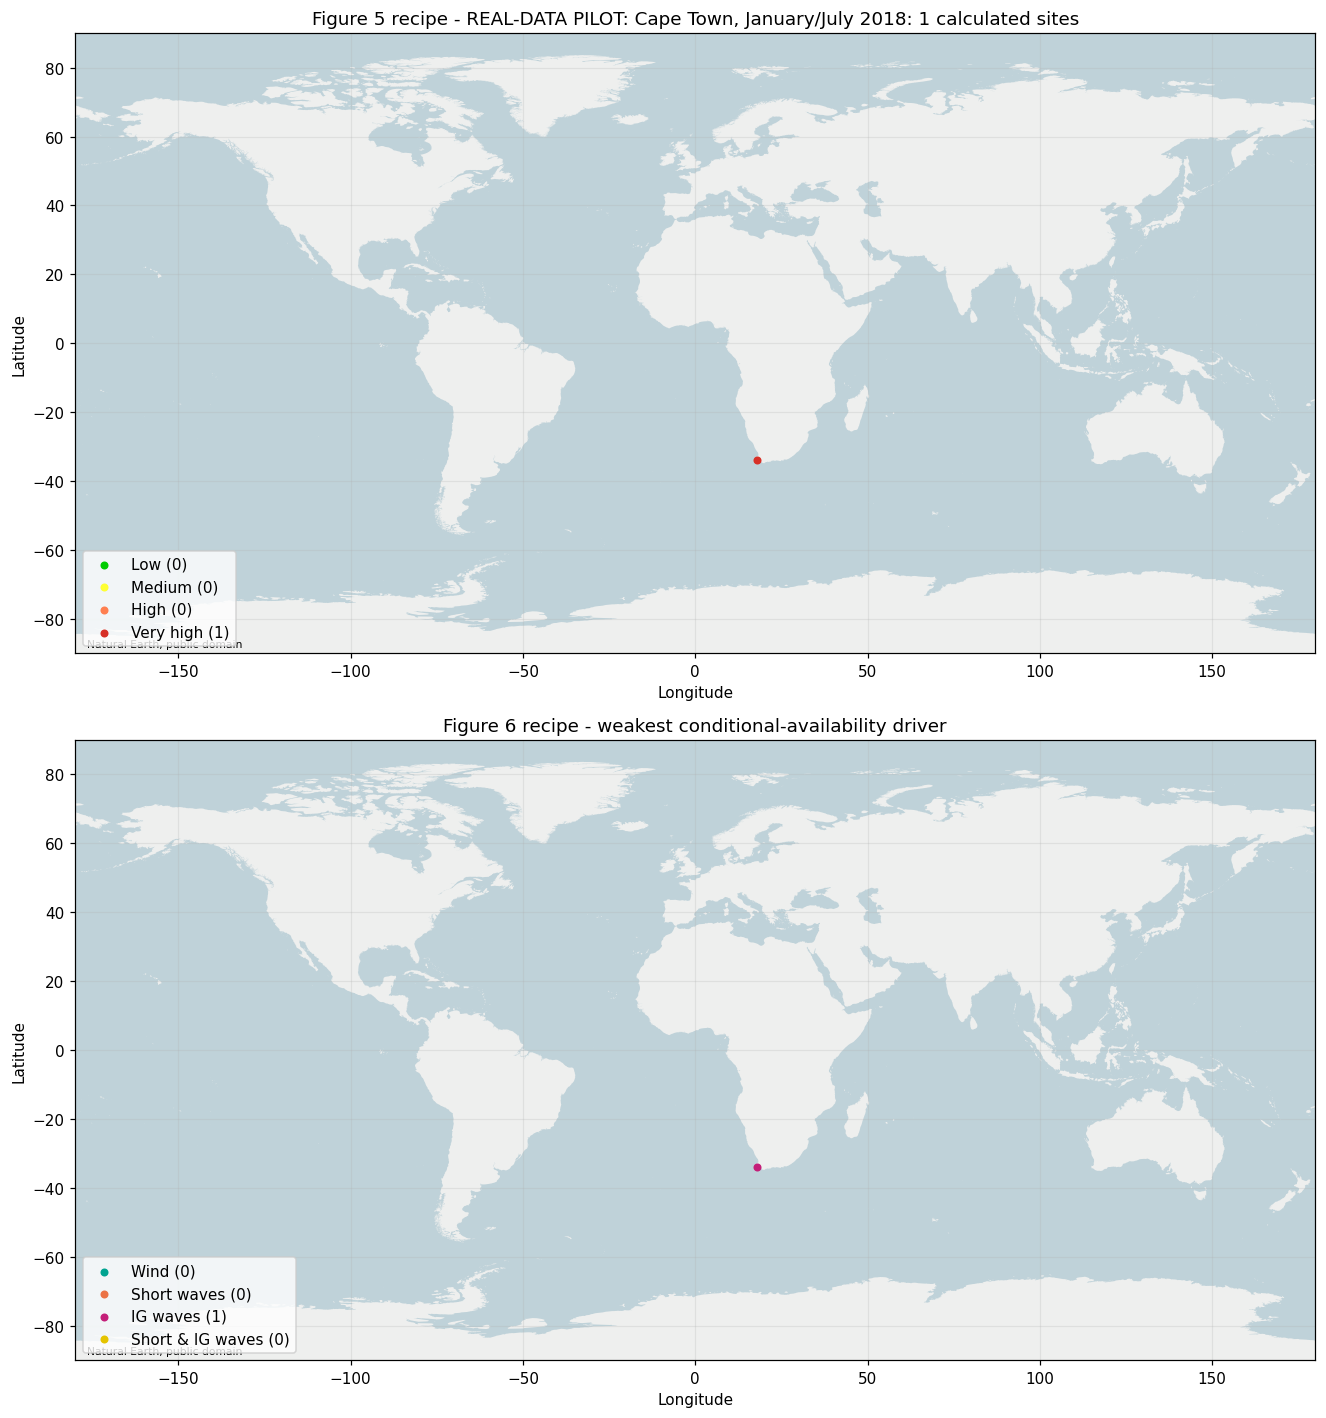

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(15, 13))
for ax in axes:
    world_axes(ax)
for risk, colour in RISK_COLOURS.items():
    group = baseline.loc[baseline.risk.astype(str).eq(risk)]
    axes[0].scatter(group.lon, group.lat, c=colour, s=18, label=f'{risk} ({len(group)})', zorder=3)
driver_colours = {'Wind': '#00a390', 'Short waves': '#eb7245', 'IG waves': '#c41e79', 'Short & IG waves': '#e5c400'}
for driver, colour in driver_colours.items():
    group = baseline.loc[baseline.main_driver.eq(driver)]
    axes[1].scatter(group.lon, group.lat, c=colour, s=18, label=f'{driver} ({len(group)})', zorder=3)
axes[0].set_title(f'Figure 5 recipe - {scope_label}: {len(baseline):,} calculated sites')
axes[1].set_title('Figure 6 recipe - weakest conditional-availability driver')
for ax in axes:
    ax.legend(loc='lower left')
fig.tight_layout()
save_figure(fig, 'figures-5-6-risk-and-drivers')
plt.show()

In [10]:
risk_summary = baseline.groupby('risk', observed=True).agg(
    locations=('site_id', 'count'), availability=('total_availability', 'mean'),
    wind=('wind_availability', 'mean'), short_waves=('short_wave_availability', 'mean'),
    ig=('ig_availability', 'mean'), frequency=('frequency', 'mean'), duration=('duration', 'mean'))
risk_summary['location_percent'] = 100 * risk_summary.locations / len(baseline)
risk_summary.to_csv(PATHS['processed'] / f'{MODE}-table-3-risk-summary.csv')
driver_summary = pd.crosstab(baseline.risk, baseline.main_driver)
driver_summary.to_csv(PATHS['processed'] / f'{MODE}-table-4-driver-summary.csv')
display(risk_summary)
display(driver_summary)
published_counts = pd.Series({'Low': 2336, 'Medium': 1048, 'High': 491, 'Very high': 685}, name='Published 4560-site count')
if MODE == 'global':
    display(pd.concat([published_counts, risk_summary.locations.rename('Reconstructed-grid count')], axis=1))
else:
    print('Published global class counts are not used as calculated pilot results.')

,locations,availability,wind,short_waves,ig,frequency,duration,location_percent
risk,,,,,,,,
Very high,1,55.30914,97.513441,65.860215,61.223118,100.149194,39.117647,100.0


main_driver,IG waves
risk,
Very high,1


Published global class counts are not used as calculated pilot results.


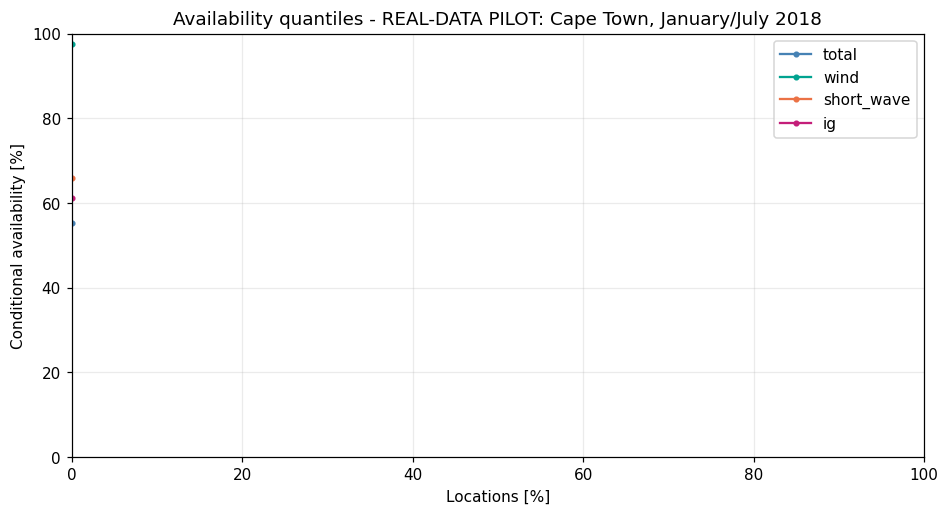

One point is not a global distribution; the full run supplies the global quantile curves.


In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
for indicator, colour in [('total', 'steelblue'), *COLOURS.items()]:
    values = np.sort(baseline[f'{indicator}_availability'].to_numpy())
    ax.plot(np.linspace(0, 100, len(values)), values, '.-', color=colour, label=indicator)
ax.set(xlim=(0, 100), ylim=(0, 100), xlabel='Locations [%]', ylabel='Conditional availability [%]', title=f'Availability quantiles - {scope_label}')
ax.legend()
save_figure(fig, 'availability-quantiles')
plt.show()
if len(baseline) == 1:
    print('One point is not a global distribution; the full run supplies the global quantile curves.')

## 9. Figure 7 / Table 5: seasonal analysis

Apply event conditioning separately to each contiguous seasonal segment. Unobserved pilot seasons are explicitly marked, never filled with zero availability. Seasonal frequency below is events per sampled calendar-year season, unlike the annualized `frequency` column.

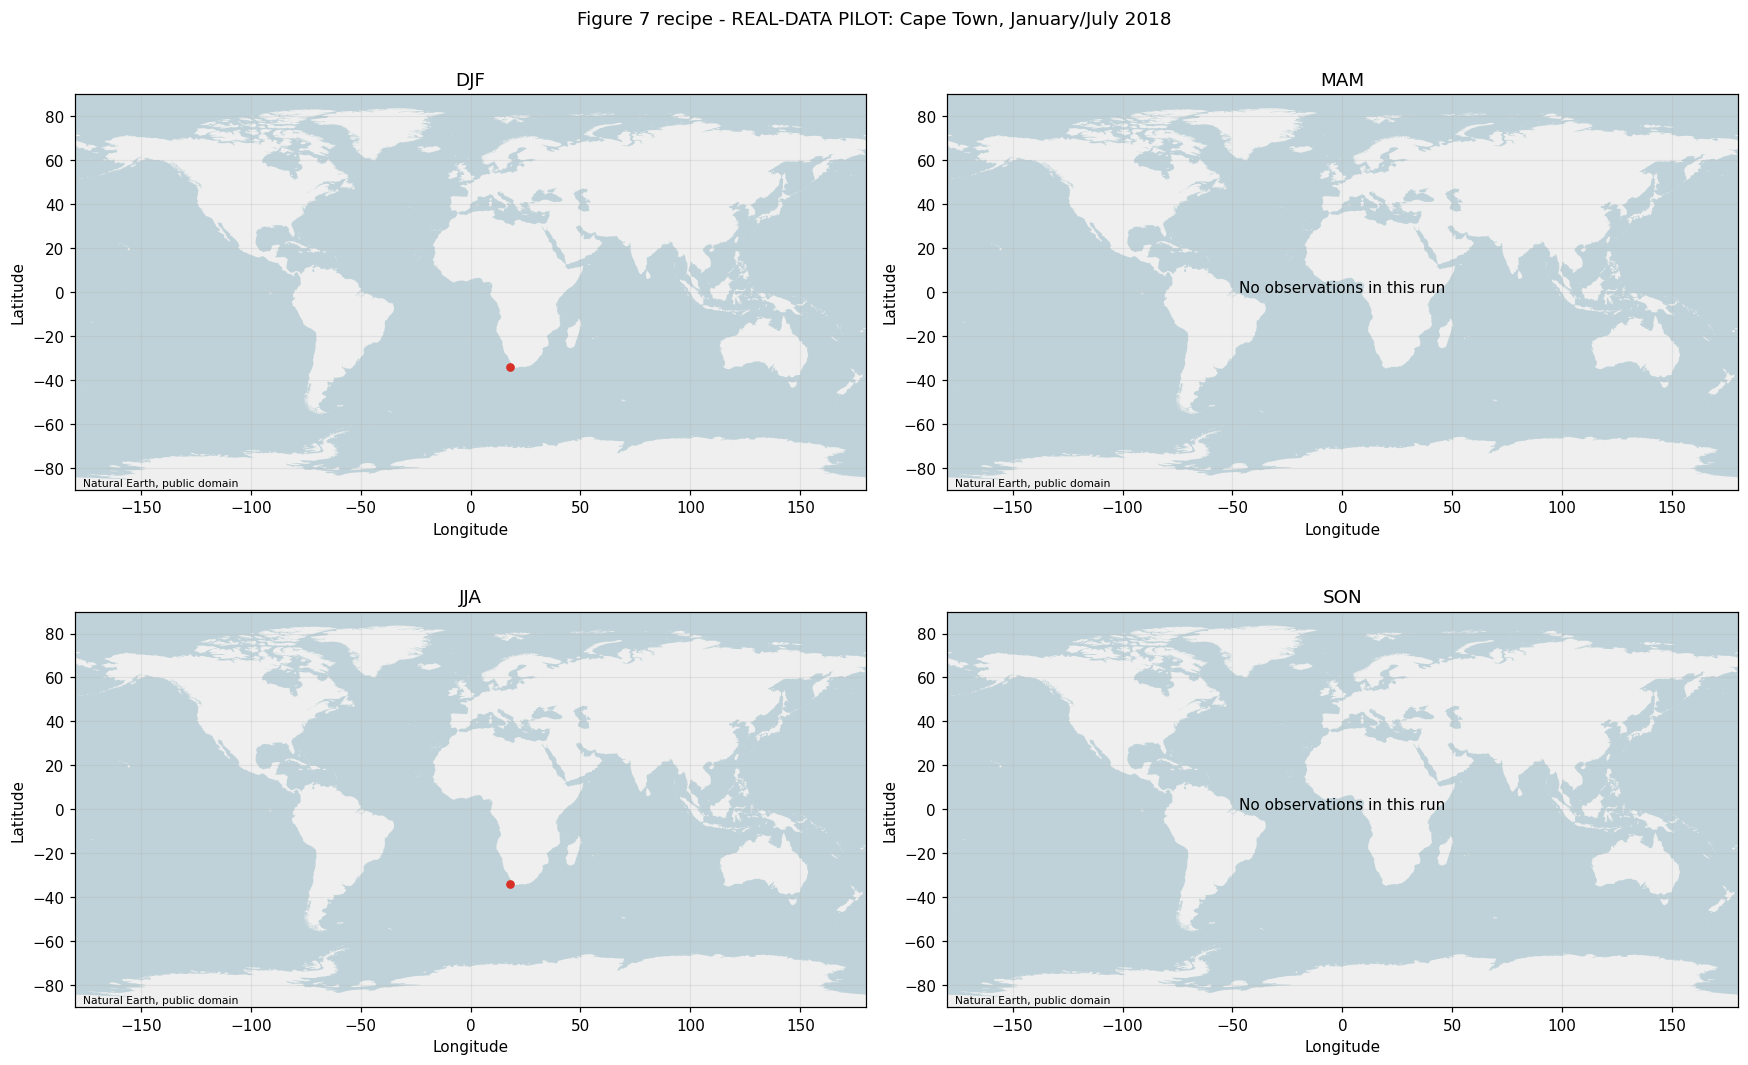

,total_availability,wind_availability,short_wave_availability,ig_availability,frequency_per_season,duration
season,,,,,,
DJF,66.263441,96.236559,79.704301,71.370968,9.0,27.888889
MAM,NaN,NaN,NaN,NaN,NaN,NaN
JJA,44.354839,98.790323,52.016129,51.075269,8.0,51.750000
SON,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
season_order = ['DJF', 'MAM', 'JJA', 'SON']
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, season in zip(axes.flat, season_order):
    world_axes(ax)
    group = seasonal_baseline.loc[seasonal_baseline.season.eq(season)].copy()
    if group.empty:
        ax.text(0.5, 0.5, 'No observations in this run', transform=ax.transAxes, ha='center')
    else:
        colours = [RISK_COLOURS[str(r)] for r in model.risk_class(group.total_availability)]
        ax.scatter(group.lon, group.lat, c=colours, s=22, zorder=3)
    ax.set_title(season)
fig.suptitle(f'Figure 7 recipe - {scope_label}')
fig.tight_layout()
save_figure(fig, 'figure-7-seasons')
plt.show()
season_table = seasonal_baseline.groupby('season')[['total_availability', 'wind_availability', 'short_wave_availability', 'ig_availability', 'frequency_per_season', 'duration']].mean().reindex(season_order)
season_table.to_csv(PATHS['processed'] / f'{MODE}-table-5-seasons.csv')
display(season_table)

## 10. Figures 8-10: annual trends, annual p95 and first/last-decade differences

Annual mean availability, event frequency and duration are averaged across the calculated sites only for calendar years with complete hourly coverage at every selected site. A trailing five-year mean requires five consecutive complete years. The last-minus-first-decade map uses 2009-2018 minus 1979-1988 and retains only sites with complete hourly coverage for every year in both decades. No synthetic annual trend or substituted decade is generated for the pilot.

In [13]:
year_counts = complete_annual.groupby('year').site_id.nunique()
complete_years = year_counts.index[year_counts.eq(len(sites))]
annual_metrics = complete_annual.loc[complete_annual.year.isin(complete_years)].groupby('year')[['total_availability', 'duration', 'frequency', 'wind_p95', 'short_wave_p95', 'ig_p95']].mean()
annual_metrics.to_csv(PATHS['processed'] / f'{MODE}-annual-mean-metrics.csv')
if len(annual_metrics) >= 2:
    for number, columns in [(8, ['total_availability', 'duration', 'frequency']), (9, ['wind_p95', 'short_wave_p95', 'ig_p95'])]:
        fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
        for ax, column in zip(axes, columns):
            ax.plot(annual_metrics.index, annual_metrics[column], label='Annual mean')
            consecutive = annual_metrics[column].reindex(range(annual_metrics.index.min(), annual_metrics.index.max()+1))
            ax.plot(consecutive.index, consecutive.rolling(5, min_periods=5).mean(), label='Trailing 5-year mean')
            ax.set_ylabel(column)
            ax.legend()
        fig.suptitle(f'Figure {number} recipe - {scope_label}')
        fig.tight_layout()
        save_figure(fig, f'figure-{number}-annual-trends')
        plt.show()
else:
    print('Figures 8-9 not generated: at least two complete calendar years at every site are required.')
first_decade, last_decade = set(range(1979, 1989)), set(range(2009, 2019))
required_years = sorted(first_decade | last_decade)
pivot = complete_annual.pivot(index='site_id', columns='year', values='total_availability').reindex(columns=required_years).dropna()
if not pivot.empty:
    change = pivot[sorted(last_decade)].mean(axis=1) - pivot[sorted(first_decade)].mean(axis=1)
    decadal = baseline[['site_id', 'lon', 'lat']].merge(change.rename('change_percentage_points'), on='site_id')
    decadal.to_csv(PATHS['processed'] / 'decadal-change.csv', index=False)
    fig, ax = plt.subplots(figsize=(15, 7))
    world_axes(ax)
    sc = ax.scatter(decadal.lon, decadal.lat, c=decadal.change_percentage_points, cmap='RdBu', vmin=-10, vmax=10, s=10, zorder=3)
    fig.colorbar(sc, ax=ax, label='Availability change [percentage points]')
    ax.set_title('Figure 10 recipe: 2009-2018 minus 1979-1988')
    save_figure(fig, 'figure-10-decadal-change')
    plt.show()
else:
    print('Figure 10 not generated: both full historical decades are required.')

Figures 8-9 not generated: at least two complete calendar years at every site are required.
Figure 10 not generated: both full historical decades are required.


## 11. Thesis sensitivity scenarios and sediment-transport proxy

The threshold experiments change all three limits together; forcing experiments increase wind and/or offshore Hs by 5%; depth experiments use 15, 16, 17 and 20 m. These are scenario sensitivities, not climate projections.

The optional thesis-style longshore proxy is `Hs_nearshore^2.5 * abs(sin(2*theta_nearshore))` for shoreward waves. It is **not a volumetric sediment-transport rate**. The legacy notebook used `sin(2*sin(theta))`; this reconstruction uses the angle itself and records that correction.

,total_availability,wind_availability,short_wave_availability,ig_availability,change_from_baseline_percentage_points
scenario,,,,,
baseline,55.309140,97.513441,65.860215,61.223118,0.000000
lower_thresholds,27.822581,85.013441,35.013441,47.782258,-27.486559
higher_thresholds,67.674731,100.000000,85.551075,69.086022,12.365591
depth_17m,43.077957,97.513441,65.591398,45.362903,-12.231183
depth_16m,38.373656,97.513441,65.322581,39.986559,-16.935484
depth_15m,33.400538,97.513441,64.986559,34.475806,-21.908602
wind_plus_5pct,55.107527,96.774194,65.860215,61.223118,-0.201613
waves_plus_5pct,48.723118,97.513441,60.551075,55.107527,-6.586022
wind_waves_plus_5pct,48.521505,96.774194,60.551075,55.107527,-6.787634


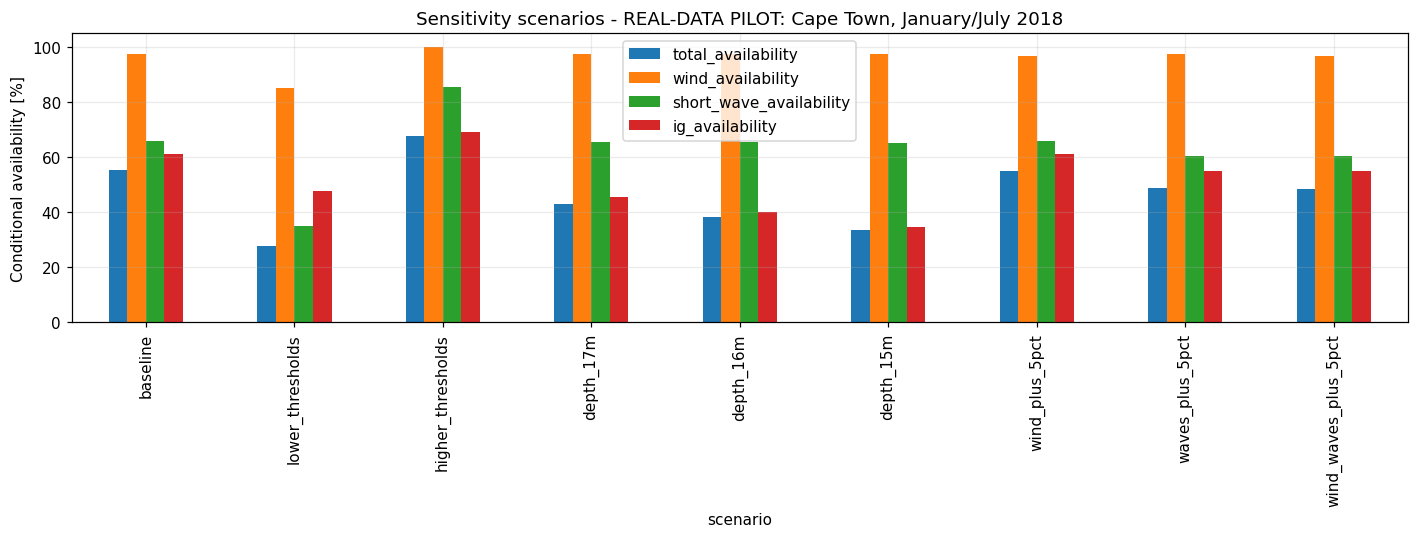

Example mean longshore proxy [m^2.5]: 4.868487936345721


In [14]:
sensitivity = summary.groupby('scenario')[['total_availability', 'wind_availability', 'short_wave_availability', 'ig_availability']].mean().reindex([s.name for s in SCENARIOS])
sensitivity['change_from_baseline_percentage_points'] = sensitivity.total_availability - sensitivity.loc['baseline', 'total_availability']
sensitivity.to_csv(PATHS['processed'] / f'{MODE}-sensitivity.csv')
display(sensitivity)
fig, ax = plt.subplots(figsize=(13, 5))
sensitivity[['total_availability', 'wind_availability', 'short_wave_availability', 'ig_availability']].plot.bar(ax=ax)
ax.set(ylabel='Conditional availability [%]', title=f'Sensitivity scenarios - {scope_label}')
fig.tight_layout()
save_figure(fig, 'sensitivity')
plt.show()
print('Example mean longshore proxy [m^2.5]:', example_indicators.sediment_proxy.mean())

## 12. Interactive check map and calculated GeoJSON

The background is an embedded simplified Natural Earth land layer, so no basemap API key or tile requests are needed. Leaflet assets still require internet access. The layer legend is collapsible and there is no information box. Calculated point GeoJSON is already saved by `run_study` as `data/processed/operability.geojson`. This is separate from the earlier **image-digitized** GeoJSON.

In [15]:
calculated_map = folium.Map(location=[12, 0], zoom_start=2, tiles=None, prefer_canvas=True)
calculated_map.get_root().header.add_child(folium.Element('<style>.leaflet-container {background:#bfd2d9 !important;}</style>'))
background = land[['geometry']].copy()
background.geometry = background.geometry.simplify(0.05, preserve_topology=True)
folium.GeoJson(json.loads(background.to_json()), name='Natural Earth land', overlay=False,
               attribution='Natural Earth (public domain)', interactive=False,
               style_function=lambda feature: {'fillColor':'#eeefee', 'fillOpacity':1, 'weight':0}).add_to(calculated_map)
for risk, colour in RISK_COLOURS.items():
    layer = folium.FeatureGroup(name=f'{risk} operability risk')
    for point in baseline.loc[baseline.risk.astype(str).eq(risk)].itertuples(index=False):
        folium.CircleMarker([point.lat, point.lon], radius=4, color=colour, fill=True, fill_opacity=1,
                            tooltip=f'{point.name}: {point.total_availability:.1f}%',
                            popup=f'Calculated availability: {point.total_availability:.2f}%<br>{scope_label}<br>Reconstructed inputs; not measured downtime.').add_to(layer)
    layer.add_to(calculated_map)
folium.LayerControl(collapsed=True).add_to(calculated_map)
calculated_map

## 13. Provenance, outputs and completion status

The manifest contains public requests, checksums and package versions, never credentials. CSV/NetCDF/GeoJSON outputs are calculated from the downloaded metocean observations. A successful pilot demonstrates the pipeline, not reproduction of the published global numbers. The 103-port original selection and the original IG table remain unavailable; reconstructed alternatives are explicitly labelled.

In [16]:
settings = {'mode': MODE, 'years': YEARS, 'months': MONTHS, 'sites': len(sites),
            'reconstructed_grid_sites': len(grid), 'scenarios': [asdict(s) for s in SCENARIOS],
            'ig_gamma': 3.3, 'ig_quadrature': [192, 72, 19],
            'scope': scope_label, 'exact_original_inputs': False}
manifest_file = model.run_manifest(DATA_ROOT, settings)
status = pd.DataFrame([
    ('Actual ERA5 retrieval and nearshore/IG calculation', 'Completed for selected scope'),
    ('Threshold/event/sensitivity datasets and maps', 'Completed for selected scope'),
    ('1979-2018 global study', 'Not run' if MODE == 'pilot' else 'See selected scope and manifest'),
    ('Original manually edited 4560-point grid', 'Unavailable; regenerated and labelled'),
    ('Original 103-port identifiers', 'Unavailable; optional supplied CSV required'),
    ('Original IG lookup', 'Unavailable; reconstructed spectral assumptions recorded'),
], columns=['Component', 'Status'])
status.to_csv(PATHS['processed'] / 'reproduction-status.csv', index=False)
display(status)
print('Manifest:', manifest_file.resolve())
print('Calculated GeoJSON:', (PATHS['processed'] / 'operability.geojson').resolve())
print('Figure files:', len(list(PATHS['figures'].glob(f'{MODE}-*.png'))))

,Component,Status
0,Actual ERA5 retrieval and nearshore/IG calcula...,Completed for selected scope
1,Threshold/event/sensitivity datasets and maps,Completed for selected scope
2,1979-2018 global study,Not run
3,Original manually edited 4560-point grid,Unavailable; regenerated and labelled
4,Original 103-port identifiers,Unavailable; optional supplied CSV required
5,Original IG lookup,Unavailable; reconstructed spectral assumption...


Manifest: /Users/mvankoningsveld/Library/CloudStorage/OneDrive-DelftUniversityofTechnology/github/Port-Operability-Metocean/data/processed/run-manifest.json
Calculated GeoJSON: /Users/mvankoningsveld/Library/CloudStorage/OneDrive-DelftUniversityofTechnology/github/Port-Operability-Metocean/data/processed/operability.geojson
Figure files: 6
